In [ ]:
from google.colab import files
import pandas as pd

# Prompts you to upload the file from your local machine
uploaded = files.upload()

# Get the uploaded CSV filename automatically
csv_file_path = list(uploaded.keys())[0]
df = pd.read_csv(csv_file_path)

Saving streaming_content_trends.csv to streaming_content_trends (2).csv


Dataset Shape: (988, 14)

First 5 rows:
  search_category media_type       id                      title  \
0         popular      movie   969681  Spider-Man: Brand New Day   
1         popular      movie  1368337                The Odyssey   
2         popular      movie  1288445                     Mutiny   
3         popular      movie  1084244                Toy Story 5   
4         popular      movie  1323244              Rage of Stars   

  original_language                                genres release_date  \
0                en    Science Fiction, Action, Adventure   2026-07-29   
1                en            Adventure, Action, Fantasy   2026-07-15   
2                en                      Action, Thriller   2026-08-19   
3                en  Animation, Family, Comedy, Adventure   2026-06-17   
4                en     Action, Science Fiction, Thriller   2026-08-06   

   popularity  vote_average  vote_count origin_country  \
0   1657.2333         7.900        2098         

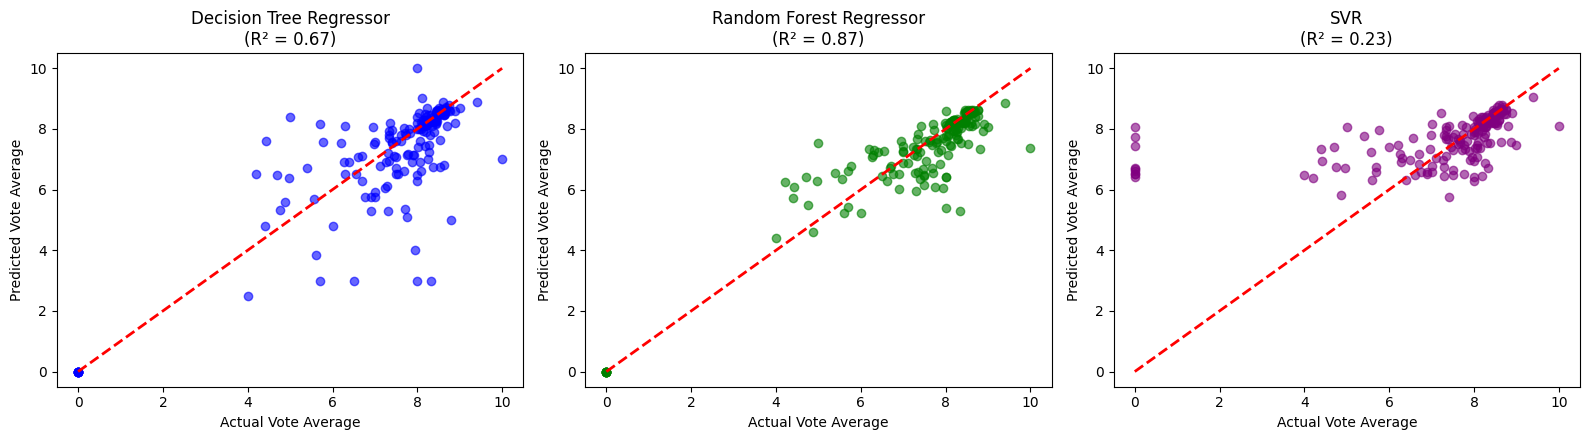

In [ ]:
# ==========================================
# STREAMING CONTENT REGRESSION
# Decision Tree, Random Forest, and SVR
# Target: vote_average (Continuous Target)
# ==========================================

import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor

# ==========================================
# 1. LOAD DATASET
# ==========================================

# Auto-detect path in Google Colab environment or fallback to default filename
if "csv_file_path" in globals() and os.path.exists(csv_file_path):
    file_path = csv_file_path
elif "path" in globals() and os.path.exists(path):
    file_path = path
elif os.path.exists("streaming_content_trends_3.csv"):
    file_path = "streaming_content_trends_3.csv"
else:
    file_path = "streaming_content_trends.csv"

df = pd.read_csv(file_path)

print("Dataset Shape:", df.shape)
print("\nFirst 5 rows:")
print(df.head())


# ==========================================
# 2. FEATURE ENGINEERING & PREPROCESSING
# ==========================================

# Drop rows missing crucial modeling features or target
df = df.dropna(
    subset=["release_year", "genres", "media_type", "vote_average"]
).copy()

# Extract primary genre from multi-genre string
df["primary_genre"] = df["genres"].apply(
    lambda x: str(x).split(",")[0].strip()
)

# Select features for regression
features = [
    "search_category",
    "media_type",
    "original_language",
    "primary_genre",
    "vote_count",
    "popularity",
    "release_year",
    "is_recent",
]

X = df[features].copy()
y = df["vote_average"]


# ==========================================
# 3. ENCODE CATEGORICAL DATA
# ==========================================

le = LabelEncoder()

# Encode predictor categorical variables
for column in X.select_dtypes(include=["object", "bool"]).columns:
    X[column] = le.fit_transform(X[column].astype(str))


# ==========================================
# 4. TRAIN-TEST SPLIT
# ==========================================

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))


# ==========================================
# 5. DECISION TREE REGRESSOR
# ==========================================

dt_reg = DecisionTreeRegressor(random_state=42)
dt_reg.fit(X_train, y_train)

dt_pred = dt_reg.predict(X_test)

dt_mse = mean_squared_error(y_test, dt_pred)
dt_mae = mean_absolute_error(y_test, dt_pred)
dt_r2 = r2_score(y_test, dt_pred)


# ==========================================
# 6. RANDOM FOREST REGRESSOR
# ==========================================

rf_reg = RandomForestRegressor(n_estimators=100, random_state=42)
rf_reg.fit(X_train, y_train)

rf_pred = rf_reg.predict(X_test)

rf_mse = mean_squared_error(y_test, rf_pred)
rf_mae = mean_absolute_error(y_test, rf_pred)
rf_r2 = r2_score(y_test, rf_pred)


# ==========================================
# 7. SUPPORT VECTOR REGRESSOR (SVR)
# ==========================================

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

svr_reg = SVR(kernel="rbf")
svr_reg.fit(X_train_scaled, y_train)

svr_pred = svr_reg.predict(X_test_scaled)

svr_mse = mean_squared_error(y_test, svr_pred)
svr_mae = mean_absolute_error(y_test, svr_pred)
svr_r2 = r2_score(y_test, svr_pred)


# ==========================================
# 8. DISPLAY RESULTS
# ==========================================

print("\n==========================================")
print("          REGRESSION MODEL RESULTS")
print("==========================================")

print("\nDECISION TREE REGRESSOR")
print("-------------------------")
print("MSE     :", dt_mse)
print("MAE     :", dt_mae)
print("R2 Score:", dt_r2)

print("\nRANDOM FOREST REGRESSOR")
print("-------------------------")
print("MSE     :", rf_mse)
print("MAE     :", rf_mae)
print("R2 Score:", rf_r2)

print("\nSUPPORT VECTOR REGRESSOR (SVR)")
print("-------------------------")
print("MSE     :", svr_mse)
print("MAE     :", svr_mae)
print("R2 Score:", svr_r2)


# ==========================================
# 9. MODEL COMPARISON TABLE
# ==========================================

results = pd.DataFrame(
    {
        "Model": [
            "Decision Tree Regressor",
            "Random Forest Regressor",
            "Support Vector Regressor (SVR)",
        ],
        "Mean Squared Error (MSE)": [dt_mse, rf_mse, svr_mse],
        "Mean Absolute Error (MAE)": [dt_mae, rf_mae, svr_mae],
        "R2 Score": [dt_r2, rf_r2, svr_r2],
    }
)

print("\n==========================================")
print("             MODEL COMPARISON")
print("==========================================")
print(results.to_string(index=False))


# ==========================================
# 10. VISUALIZE ACTUAL VS PREDICTED
# ==========================================

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# Decision Tree Plot
axes[0].scatter(y_test, dt_pred, alpha=0.6, color="blue")
axes[0].plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--",
    lw=2,
)
axes[0].set_title(f"Decision Tree Regressor\n(R² = {dt_r2:.2f})")
axes[0].set_xlabel("Actual Vote Average")
axes[0].set_ylabel("Predicted Vote Average")

# Random Forest Plot
axes[1].scatter(y_test, rf_pred, alpha=0.6, color="green")
axes[1].plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--",
    lw=2,
)
axes[1].set_title(f"Random Forest Regressor\n(R² = {rf_r2:.2f})")
axes[1].set_xlabel("Actual Vote Average")
axes[1].set_ylabel("Predicted Vote Average")

# SVR Plot
axes[2].scatter(y_test, svr_pred, alpha=0.6, color="purple")
axes[2].plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--",
    lw=2,
)
axes[2].set_title(f"SVR\n(R² = {svr_r2:.2f})")
axes[2].set_xlabel("Actual Vote Average")
axes[2].set_ylabel("Predicted Vote Average")

plt.tight_layout()
plt.show()